# Popularidad, evolución y finanzas

Este notebook integra las películas y series de Netflix disponibles para estudiar la popularidad, la valoración, la evolución histórica del catálogo y el retorno financiero de las películas.

In [94]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


import sys
import os

sys.path.append(os.path.abspath(".."))

from src.negocio import agregar_control_financiero
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda value: f'{value:,.2f}')

NOTEBOOK_DIR = Path.cwd()
if NOTEBOOK_DIR.name != 'notebooks':
    NOTEBOOK_DIR = NOTEBOOK_DIR / 'notebooks'
DATA_DIR = NOTEBOOK_DIR.parent / 'data'
MOVIES_PATH = DATA_DIR / 'netflix_movies_detailed_up_to_2025.csv'
SHOWS_PATH = DATA_DIR / 'netflix_tv_shows_detailed_up_to_2025.csv'

def mostrar_titulo(texto):
    print(f'\n{texto}\n' + '-' * len(texto))

def porcentaje(valor, total):
    return 100 * valor / total if total else 0

## 1. Carga y consolidación

Los archivos se combinan conservando una columna `source_file`. Se usan rutas relativas para que el notebook siga funcionando desde la carpeta del proyecto.

In [95]:
movies = pd.read_csv(MOVIES_PATH, low_memory=False)
shows = pd.read_csv(SHOWS_PATH, low_memory=False)
movies['source_file'] = 'movies'
shows['source_file'] = 'tv_shows'
catalogo = pd.concat([movies, shows], ignore_index=True, sort=False)

print(f'Películas: {movies.shape[0]:,} filas, {movies.shape[1]:,} columnas')
print(f'Series: {shows.shape[0]:,} filas, {shows.shape[1]:,} columnas')
print(f'Catálogo consolidado: {catalogo.shape[0]:,} filas, {catalogo.shape[1]:,} columnas')
display(catalogo.head())
display(pd.DataFrame({'tipo': catalogo.dtypes.astype(str), 'nulos': catalogo.isna().sum(), 'nulos_pct': (catalogo.isna().mean() * 100).round(2)}))

Películas: 16,000 filas, 19 columnas
Series: 16,000 filas, 17 columnas
Catálogo consolidado: 32,000 filas, 19 columnas


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,genres,language,description,popularity,vote_count,vote_average,budget,revenue,source_file
0,10192,Movie,Shrek Forever After,Mike Mitchell,"Mike Myers, Eddie Murphy, Cameron Diaz, Antoni...",United States of America,2010-05-16,2010,6.38,NaN,"Comedy, Adventure, Fantasy, Animation, Family",en,A bored and domesticated Shrek pacts with deal...,203.89,7449,6.38,"165,000,000.00","752,600,867.00",movies
1,27205,Movie,Inception,Christopher Nolan,"Leonardo DiCaprio, Joseph Gordon-Levitt, Ken W...","United Kingdom, United States of America",2010-07-15,2010,8.37,NaN,"Action, Science Fiction, Adventure",en,"Cobb, a skilled thief who commits corporate es...",156.24,37119,8.37,"160,000,000.00","839,030,630.00",movies
2,12444,Movie,Harry Potter and the Deathly Hallows: Part 1,David Yates,"Daniel Radcliffe, Emma Watson, Rupert Grint, T...","United Kingdom, United States of America",2010-11-17,2010,7.74,NaN,"Adventure, Fantasy",en,"Harry, Ron and Hermione walk away from their l...",121.19,19327,7.74,"250,000,000.00","954,305,868.00",movies
3,38757,Movie,Tangled,"Byron Howard, Nathan Greno","Mandy Moore, Zachary Levi, Donna Murphy, Ron P...",United States of America,2010-11-24,2010,7.60,NaN,"Animation, Family, Adventure",en,"Feisty teenager Rapunzel, who has long and mag...",111.76,11638,7.60,"260,000,000.00","592,461,732.00",movies
4,10191,Movie,How to Train Your Dragon,"Chris Sanders, Dean DeBlois","Jay Baruchel, Gerard Butler, Craig Ferguson, A...",United States of America,2010-03-18,2010,7.80,NaN,"Fantasy, Adventure, Animation, Family",en,As the son of a Viking leader on the cusp of m...,110.04,13259,7.80,"165,000,000.00","494,879,471.00",movies


,tipo,nulos,nulos_pct
show_id,int64,0,0.00
type,object,0,0.00
title,object,0,0.00
director,object,11097,34.68
cast,object,1361,4.25
country,object,2263,7.07
date_added,object,0,0.00
release_year,int64,0,0.00
rating,float64,0,0.00
duration,object,16000,50.00


## 2. Preparación de variables

En esta etapa se preparan las variables necesarias para el análisis. Se normalizan los nombres de las columnas, los textos, las fechas y los formatos numéricos.La revisión de duplicados, valores nulos y valores no numéricos fue realizada previamente durante la limpieza de los archivos originales.

In [96]:
def preparar_catalogo(df):
    df = df.copy()
    df.columns = df.columns.str.lower().str.strip()

    columnas_texto = [
        'type', 'title', 'director', 'cast', 'country',
        'genres', 'language', 'description', 'rating'
    ]
    for col in columnas_texto:
        if col in df.columns:
            df[col] = df[col].astype('string').str.strip()

    if 'type' in df.columns:
        df['type'] = df['type'].replace({
            'Movie': 'Movie',
            'TV Show': 'TV Show',
            'Tv Show': 'TV Show'
        })

    if 'date_added' in df.columns:
        df['date_added'] = pd.to_datetime(df['date_added'], errors='coerce')

    columnas_numericas = [
        'show_id', 'release_year', 'popularity',
        'vote_count', 'vote_average', 'budget', 'revenue'
    ]
    for col in columnas_numericas:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors='coerce')

    return df

catalogo = preparar_catalogo(catalogo)
display(catalogo[['type', 'title', 'date_added', 'release_year', 'popularity', 'vote_average']].head())

,type,title,date_added,release_year,popularity,vote_average
0,Movie,Shrek Forever After,2010-05-16,2010,203.89,6.38
1,Movie,Inception,2010-07-15,2010,156.24,8.37
2,Movie,Harry Potter and the Deathly Hallows: Part 1,2010-11-17,2010,121.19,7.74
3,Movie,Tangled,2010-11-24,2010,111.76,7.60
4,Movie,How to Train Your Dragon,2010-03-18,2010,110.04,7.80


## 3. Exploración analítica complementaria

Se comparan volumen, popularidad, votos y valoración entre películas y series.

,contenidos,popularidad_mediana,popularidad_promedio,valoracion_mediana,votos_mediana
type,,,,,
Movie,16000,10.91,20.38,6.30,138.00
TV Show,16000,36.19,64.85,6.80,4.00


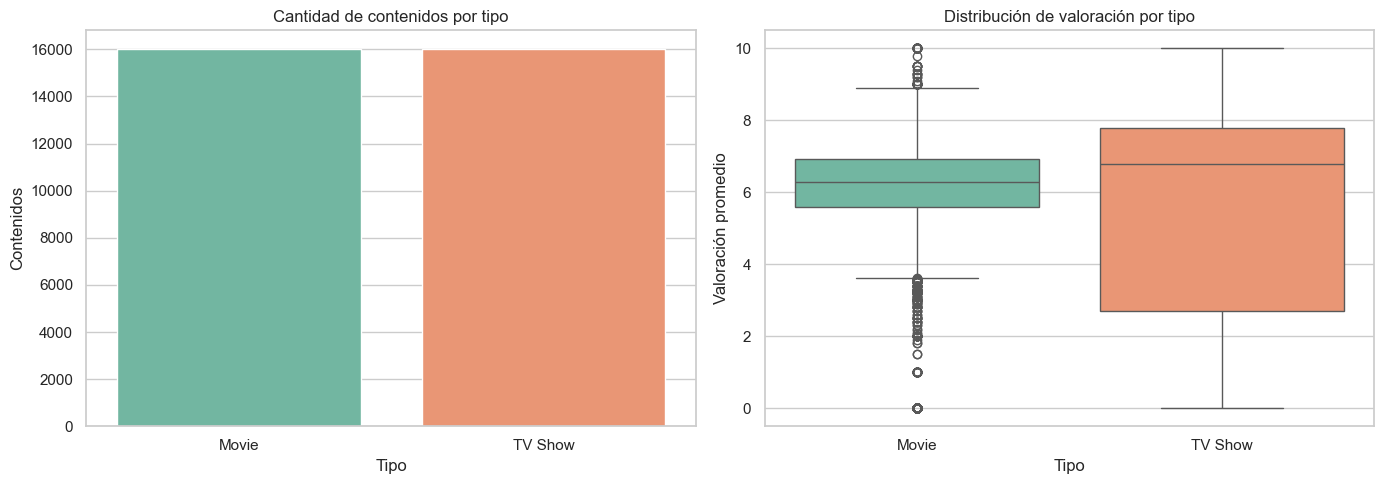

In [97]:
resumen_tipo = catalogo.groupby('type').agg(
    contenidos=('title', 'count'),
    popularidad_mediana=('popularity', 'median'),
    popularidad_promedio=('popularity', 'mean'),
    valoracion_mediana=('vote_average', 'median'),
    votos_mediana=('vote_count', 'median'),
).sort_values('contenidos', ascending=False)
display(resumen_tipo)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(data=catalogo, x='type', hue='type', legend=False, ax=axes[0], palette='Set2')
axes[0].set_title('Cantidad de contenidos por tipo')
axes[0].set_xlabel('Tipo'); axes[0].set_ylabel('Contenidos')
sns.boxplot(data=catalogo, x='type', y='vote_average', hue='type', legend=False, ax=axes[1], palette='Set2')
axes[1].set_title('Distribución de valoración por tipo')
axes[1].set_xlabel('Tipo'); axes[1].set_ylabel('Valoración promedio')
plt.tight_layout(); plt.show()

## 4. KPI financieros y variables derivadas

Regla de negocio: una película entra al análisis financiero solamente si `budget` e `revenue` son finitos y estrictamente mayores que cero. Las unidades financieras ya fueron normalizadas en la sección 2.

$ROI = \frac{revenue - budget}{budget} \times 100$

Las series no se mezclan en este cálculo porque estos archivos no entregan presupuesto ni ingresos comparables para ellas.

In [98]:
finanzas = catalogo.loc[catalogo['type'].eq('Movie')].copy()
peliculas_antes = len(finanzas)

mask_financiera = (
    np.isfinite(finanzas['budget']) & np.isfinite(finanzas['revenue'])
    & (finanzas['budget'] > 0) & (finanzas['revenue'] > 0)
)
finanzas = finanzas.loc[mask_financiera].copy()
finanzas['profit'] = finanzas['revenue'] - finanzas['budget']
finanzas['roi_pct'] = finanzas['profit'] / finanzas['budget'] * 100
finanzas['revenue_budget_ratio'] = finanzas['revenue'] / finanzas['budget']
finanzas['budget_musd'] = finanzas['budget'] / 1_000_000
finanzas['revenue_musd'] = finanzas['revenue'] / 1_000_000
finanzas['profit_musd'] = finanzas['profit'] / 1_000_000
finanzas['roi_band'] = pd.cut(finanzas['roi_pct'], [-np.inf, 0, 100, np.inf], labels=['Bajo', 'Medio', 'Alto'])

print(f'Películas antes del filtro financiero: {peliculas_antes:,}')
print(f'Películas con finanzas válidas: {len(finanzas):,} ({porcentaje(len(finanzas), peliculas_antes):.1f}%)')
display(finanzas[['budget', 'revenue', 'profit', 'roi_pct', 'revenue_budget_ratio']].describe().T)
display(finanzas['roi_band'].value_counts().rename_axis('roi_band').to_frame('peliculas'))

Películas antes del filtro financiero: 16,000
Películas con finanzas válidas: 3,540 (22.1%)


,count,mean,std,min,25%,50%,75%,max
budget,"3,540.00","35,582,137.65","51,186,023.80",1.00,"5,903,050.25","15,000,000.00","40,000,000.00","460,000,000.00"
revenue,"3,540.00","103,777,241.00","217,820,135.58",2.00,"4,207,729.50","23,800,000.00","95,093,018.25","2,799,439,100.00"
profit,"3,540.00","68,195,103.35","182,727,147.14","-199,545,977.00","-3,503,000.00","7,273,239.50","56,776,112.50","2,443,439,100.00"
roi_pct,"3,540.00","78,054.57","4,155,656.66",-100.00,-47.87,70.00,276.10,"245,675,900.00"
revenue_budget_ratio,"3,540.00",781.55,"41,556.57",0.00,0.52,1.70,3.76,"2,456,760.00"


,peliculas
roi_band,
Alto,1599
Bajo,1304
Medio,637


## 5. Popularidad y valoración

La popularidad suele tener una distribución sesgada; por eso el boxplot usa escala logarítmica cuando todos los valores son positivos. La correlación se calcula solo con pares completos y se reportan Pearson y Spearman.

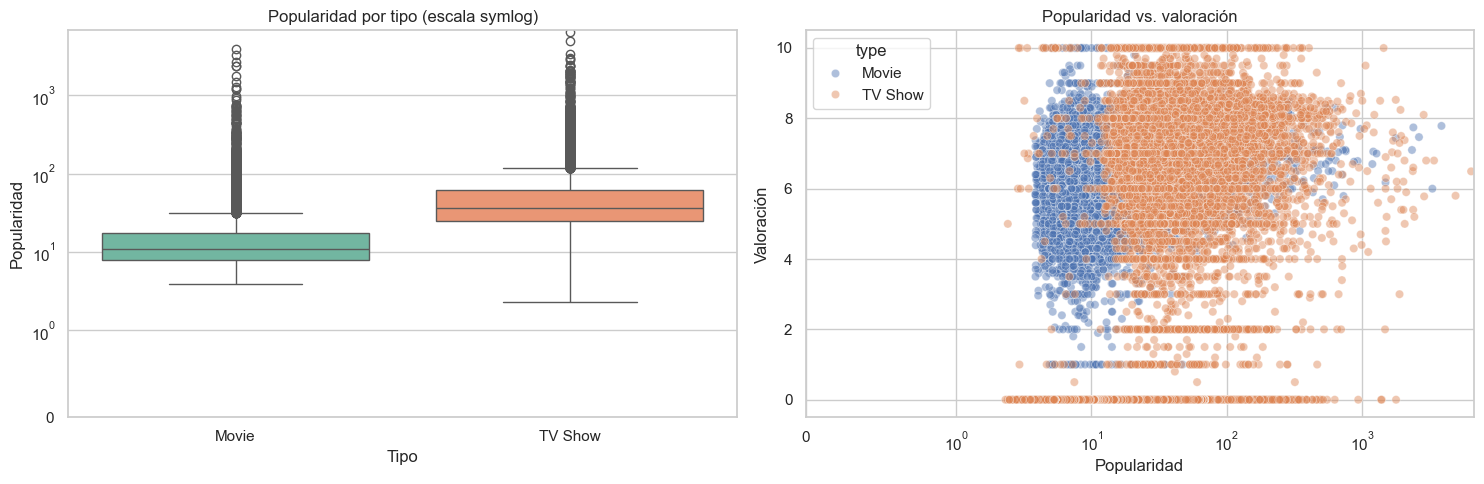

Correlación Pearson: 0.034
Correlación Spearman: 0.208


,title,type,popularity,vote_average
21000,The Late Show with Stephen Colbert,TV Show,"6,421.92",6.49
20000,The Tonight Show Starring Jimmy Fallon,TV Show,"4,925.25",5.80
15000,The Gorge,Movie,"3,876.01",7.79
18000,Good Mythical Morning,TV Show,"3,414.47",6.80
15001,Flight Risk,Movie,"3,320.62",6.00
24000,Chronicles of the Sun,TV Show,"2,987.49",6.80
30000,Volta por Cima,TV Show,"2,885.72",5.78
30001,She's the One,TV Show,"2,862.87",8.10
14000,Mufasa: The Lion King,Movie,"2,643.63",7.47
30004,Crazy About You,TV Show,"2,442.24",5.20


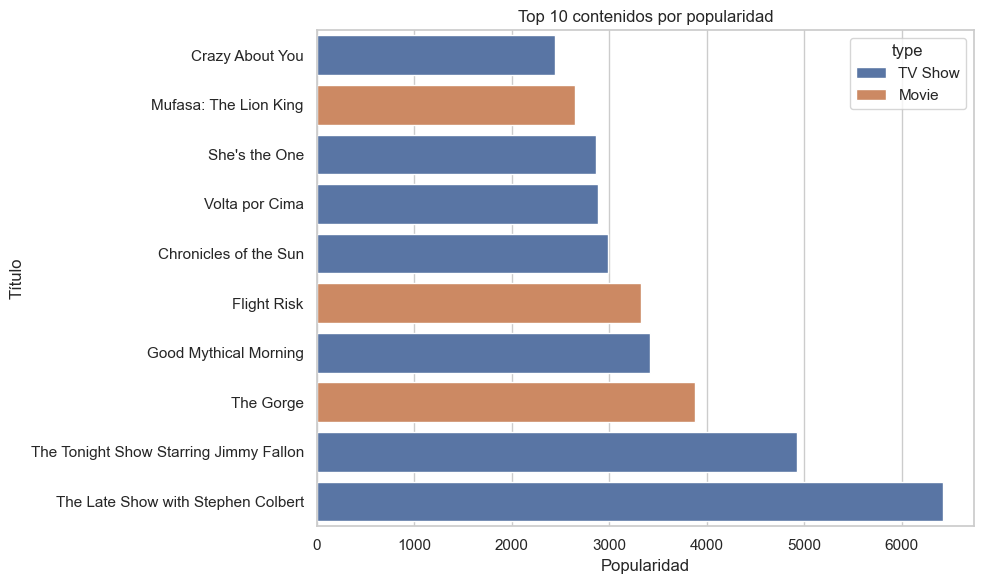

El contenido más popular es 'The Late Show with Stephen Colbert' (TV Show) con popularidad 6421.92.


In [99]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=catalogo, x='type', y='popularity', hue='type', legend=False, ax=axes[0], palette='Set2')
axes[0].set_yscale('symlog', linthresh=1)
axes[0].set_ylim(bottom=0)
axes[0].set_title('Popularidad por tipo (escala symlog)')
axes[0].set_xlabel('Tipo'); axes[0].set_ylabel('Popularidad')
sns.scatterplot(data=catalogo, x='popularity', y='vote_average', hue='type', alpha=.45, ax=axes[1])
axes[1].set_xscale('symlog', linthresh=1)
axes[1].set_xlim(left=0)
axes[1].set_title('Popularidad vs. valoración')
axes[1].set_xlabel('Popularidad'); axes[1].set_ylabel('Valoración')
plt.tight_layout(); plt.show()

pares = catalogo[['popularity', 'vote_average']].dropna()
pearson_pop_rating = pares.corr(method='pearson').iloc[0, 1]
spearman_pop_rating = pares.corr(method='spearman').iloc[0, 1]
print(f'Correlación Pearson: {pearson_pop_rating:.3f}')
print(f'Correlación Spearman: {spearman_pop_rating:.3f}')
top_populares = catalogo.nlargest(10, 'popularity')[['title', 'type', 'popularity', 'vote_average']]
display(top_populares)
plt.figure(figsize=(10, 6))
sns.barplot(data=top_populares.sort_values('popularity'), x='popularity', y='title', hue='type', dodge=False)
plt.xlim(left=0)
plt.title('Top 10 contenidos por popularidad'); plt.xlabel('Popularidad'); plt.ylabel('Título'); plt.tight_layout(); plt.show()
lider = top_populares.iloc[0]
print(f"El contenido más popular es '{lider['title']}' ({lider['type']}) con popularidad {lider['popularity']:.2f}.")

## 6. Evolución temporal del catálogo

Se usa `release_year` como año de producción. Los años fuera del intervalo razonable 1900-máximo observado se excluyen de las tendencias para no distorsionar el gráfico.

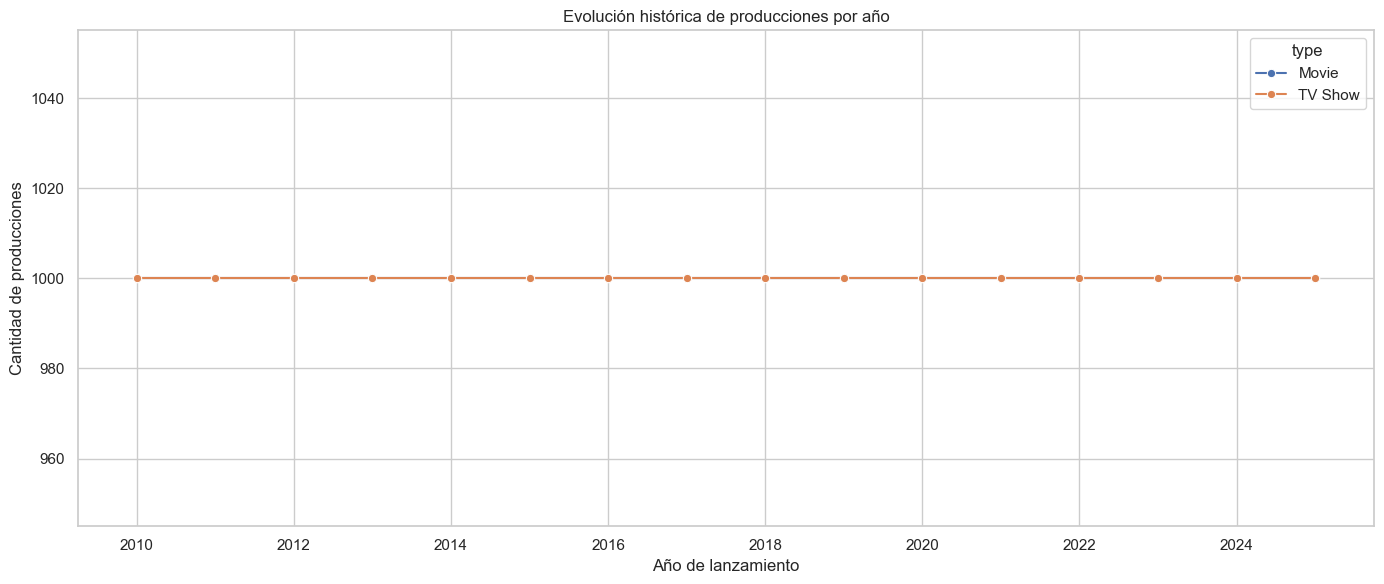

type,Movie,TV Show
decada,,
2010,10000,10000
2020,6000,6000


El año con más producciones en el catálogo es 2010, con 2,000 títulos.
El periodo analizado va de 2010 a 2025.


In [100]:
max_year = int(catalogo['release_year'].max())
temporal = catalogo.loc[catalogo['release_year'].between(1900, max_year)].copy()
por_anio = temporal.groupby(['release_year', 'type']).size().reset_index(name='producciones')
tabla_anual = por_anio.pivot(index='release_year', columns='type', values='producciones').fillna(0)
tabla_anual['Total'] = tabla_anual.sum(axis=1)

plt.figure(figsize=(14, 6))
sns.lineplot(data=por_anio, x='release_year', y='producciones', hue='type', marker='o')
plt.title('Evolución histórica de producciones por año')
plt.xlabel('Año de lanzamiento'); plt.ylabel('Cantidad de producciones'); plt.tight_layout(); plt.show()

temporal['decada'] = (temporal['release_year'] // 10 * 10).astype(int)
por_decada = temporal.groupby(['decada', 'type']).size().reset_index(name='producciones')
display(por_decada.pivot(index='decada', columns='type', values='producciones').fillna(0).tail(12))
pico = tabla_anual['Total'].idxmax()
print(f"El año con más producciones en el catálogo es {pico}, con {int(tabla_anual.loc[pico, 'Total']):,} títulos.")
print(f"El periodo analizado va de {int(temporal['release_year'].min())} a {max_year}.")

## 7. Análisis financiero

Los valores se expresan en millones de dólares para facilitar la lectura. La línea de referencia $revenue = budget$ separa las películas que recuperan la inversión de las que no.

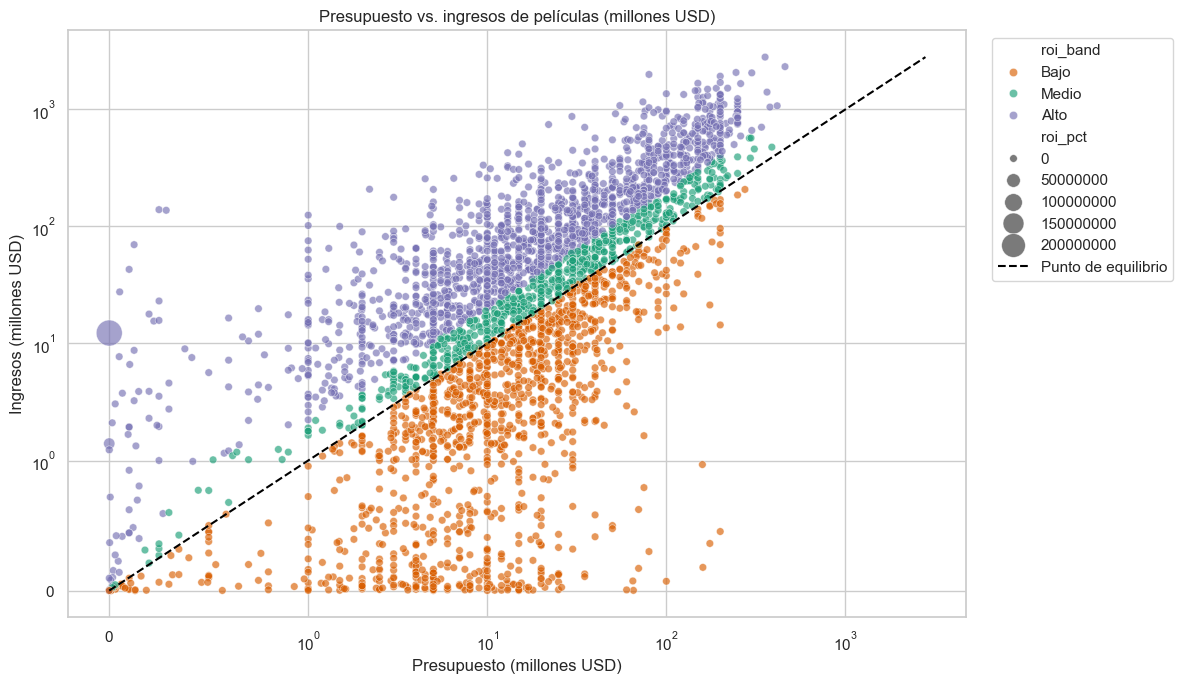

Correlación Pearson entre presupuesto e ingresos: 0.748
Top 10 por ROI:


,title,budget_musd,revenue_musd,profit_musd,roi_pct
6269,The Beatles: Eight Days a Week - The Touring Y...,0.00,12.28,12.28,"245,675,900.00"
13648,No Dogs or Italians Allowed,0.00,1.40,1.40,"27,918,340.00"
13935,Scrapper,0.00,1.23,1.23,"1,469,522.62"
12594,The Good Neighbor,0.00,0.09,0.09,"90,289.52"
8803,Animal World,0.12,69.89,69.76,"55,808.56"
5339,Mr. Six,0.25,139.19,138.94,"55,576.54"
7238,One Cut of the Dead,0.05,27.59,27.54,"52,546.99"
7739,Secret Superstar,0.29,137.42,137.13,"47,900.14"
5365,The Gallows,0.10,42.96,42.86,"42,864.41"
9258,Freaks,0.00,0.37,0.37,"18,320.50"


Top 10 por beneficio absoluto:


,title,budget_musd,revenue_musd,profit_musd,roi_pct
9001,Avengers: Endgame,356.00,"2,799.44","2,443.44",686.36
15019,Ne Zha 2,80.00,"1,990.00","1,910.00","2,387.50"
12006,Avatar: The Way of Water,460.00,"2,320.25","1,860.25",404.40
5010,Star Wars: The Force Awakens,245.00,"2,068.22","1,823.22",744.17
8000,Avengers: Infinity War,300.00,"2,052.42","1,752.42",584.14
11000,Spider-Man: No Way Home,200.00,"1,921.85","1,721.85",860.92
5001,Jurassic World,150.00,"1,671.54","1,521.54","1,014.36"
14026,Inside Out 2,200.00,"1,698.86","1,498.86",749.43
9000,The Lion King,260.00,"1,662.02","1,402.02",539.24
5008,Furious 7,190.00,"1,515.40","1,325.40",697.58


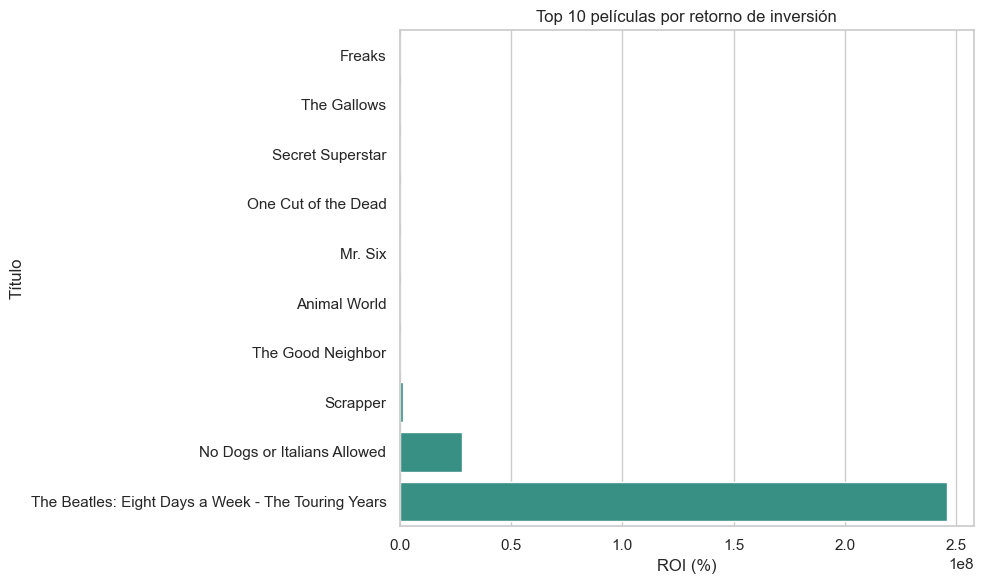

In [101]:
plt.figure(figsize=(12, 7))
sns.scatterplot(data=finanzas, x='budget_musd', y='revenue_musd', size='roi_pct', hue='roi_band', sizes=(30, 350), alpha=.65, palette={'Bajo': '#d95f02', 'Medio': '#1b9e77', 'Alto': '#7570b3'})
limite = max(finanzas['budget_musd'].max(), finanzas['revenue_musd'].max())
plt.plot([0, limite], [0, limite], '--', color='black', label='Punto de equilibrio')
plt.xscale('symlog', linthresh=1); plt.yscale('symlog', linthresh=1)
plt.title('Presupuesto vs. ingresos de películas (millones USD)')
plt.xlabel('Presupuesto (millones USD)'); plt.ylabel('Ingresos (millones USD)'); plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left'); plt.tight_layout(); plt.show()

corr_fin = finanzas[['budget', 'revenue']].corr().iloc[0, 1]
print(f'Correlación Pearson entre presupuesto e ingresos: {corr_fin:.3f}')

print('Top 10 por ROI:')
display(finanzas.nlargest(10, 'roi_pct')[['title', 'budget_musd', 'revenue_musd', 'profit_musd', 'roi_pct']])
print('Top 10 por beneficio absoluto:')
display(finanzas.nlargest(10, 'profit_musd')[['title', 'budget_musd', 'revenue_musd', 'profit_musd', 'roi_pct']])

plt.figure(figsize=(10, 6))
roi_plot = finanzas.nlargest(10, 'roi_pct').sort_values('roi_pct')
sns.barplot(data=roi_plot, x='roi_pct', y='title', color='#2a9d8f')
plt.title('Top 10 películas por retorno de inversión'); plt.xlabel('ROI (%)'); plt.ylabel('Título'); plt.tight_layout(); plt.show()

## 8. Storytelling y conclusiones

Las siguientes conclusiones se generan con los resultados calculados, para que el relato se actualice al cambiar los datos.

In [102]:
top = catalogo.nlargest(1, 'popularity').iloc[0]
tipo_pop = resumen_tipo['popularidad_mediana'].idxmax()
roi_top = finanzas.nlargest(1, 'roi_pct').iloc[0]
profit_top = finanzas.nlargest(1, 'profit_musd').iloc[0]

print('CONCLUSIONES')
print(f"1. Popularidad: {top['title']} ({top['type']}) lidera el catálogo con {top['popularity']:.2f} puntos de popularidad.")
print(f'2. Comparación: la mediana de popularidad más alta corresponde a {tipo_pop}.')
print(f'3. Popularidad y valoración: Pearson = {pearson_pop_rating:.3f}; esta magnitud debe interpretarse como una asociación, no como causalidad.')
print(f'4. Evolución: el máximo volumen de producciones aparece en {pico}; la composición por tipo se observa en la línea temporal y la tabla por década.')
print(f"5. Retorno: {roi_top['title']} presenta el ROI más alto ({roi_top['roi_pct']:,.1f}%), mientras que {profit_top['title']} lidera el beneficio absoluto ({profit_top['profit_musd']:,.1f} millones USD).")
print(f'6. Presupuesto e ingresos: la correlación es {corr_fin:.3f}; el scatter permite distinguir escala de inversión, recuperación y valores extremos.')
print('7. Limitaciones: el catálogo puede no ser exhaustivo; las finanzas solo están disponibles para una parte de las películas; los extremos pueden dominar promedios y correlación no implica causalidad.')

CONCLUSIONES
1. Popularidad: The Late Show with Stephen Colbert (TV Show) lidera el catálogo con 6421.92 puntos de popularidad.
2. Comparación: la mediana de popularidad más alta corresponde a TV Show.
3. Popularidad y valoración: Pearson = 0.034; esta magnitud debe interpretarse como una asociación, no como causalidad.
4. Evolución: el máximo volumen de producciones aparece en 2010; la composición por tipo se observa en la línea temporal y la tabla por década.
5. Retorno: The Beatles: Eight Days a Week - The Touring Years presenta el ROI más alto (245,675,900.0%), mientras que Avengers: Endgame lidera el beneficio absoluto (2,443.4 millones USD).
6. Presupuesto e ingresos: la correlación es 0.748; el scatter permite distinguir escala de inversión, recuperación y valores extremos.
7. Limitaciones: el catálogo puede no ser exhaustivo; las finanzas solo están disponibles para una parte de las películas; los extremos pueden dominar promedios y correlación no implica causalidad.


In [ ]:
df_movies = agregar_control_financiero(finanzas)

In [104]:
df_movies[
    ["title", "budget", "revenue", "budget_status", "revenue_status"]
].head(20)

,title,budget,revenue,budget_status,revenue_status
0,Shrek Forever After,"165,000,000.00","752,600,867.00",Escala consistente,Escala consistente
1,Inception,"160,000,000.00","839,030,630.00",Escala consistente,Escala consistente
2,Harry Potter and the Deathly Hallows: Part 1,"250,000,000.00","954,305,868.00",Escala consistente,Escala consistente
3,Tangled,"260,000,000.00","592,461,732.00",Escala consistente,Escala consistente
4,How to Train Your Dragon,"165,000,000.00","494,879,471.00",Escala consistente,Escala consistente
5,Shutter Island,"80,000,000.00","294,804,195.00",Escala consistente,Escala consistente
6,The Karate Kid,"40,000,000.00","359,126,022.00",Escala consistente,Escala consistente
7,Iron Man 2,"200,000,000.00","623,933,331.00",Escala consistente,Escala consistente
8,Grown Ups,"80,000,000.00","271,430,189.00",Escala consistente,Escala consistente
10,Despicable Me,"69,000,000.00","543,284,256.00",Escala consistente,Escala consistente


In [105]:
from src.negocio import resumen_financiero

import sys
import os

resumen = resumen_financiero(df_movies)
resumen

{'total_registros': 3540,
 'budget_revisar': np.int64(154),
 'budget_consistente': np.int64(3386),
 'revenue_revisar': np.int64(448),
 'revenue_consistente': np.int64(3092)}